# ANN Hackathon — Generic Template + Worked Sample

**Sample problem (Theme 0, faculty demo): Signal Type Recognition** — a neural network listens to a short, noisy signal and says whether it is a **sine, square, triangle or sawtooth** wave.

This notebook has two jobs:

1. **Template** — the same 12 steps work for *every* hackathon theme (ECG, radio, bearings, crops, keywords, roads). Cells marked **🔁 CHANGE FOR YOUR THEME** are the only ones a team needs to edit.
2. **Worked sample** — every step is already solved for the waveform problem, so you can see what "done" looks like.

| Step | What you do | Concept (syllabus link) |
|---|---|---|
| 0 | Setup & config | Reproducibility (random seeds) |
| 1 | Frame the problem | Fitting / pattern recognition / clustering / prediction (Unit 5) |
| 2 | Load the data | Selection of data, input range (Unit 5) |
| 3 | Explore the data | Class balance, what the inputs look like |
| 4 | Preprocess | Normalization, coding targets one-of-N (Unit 5) |
| 5 | Split train / val / test | 70 / 15 / 15, no leakage (Unit 5) |
| 6 | Baseline | Always beat something simple first |
| 7 | Build the network | Architecture, transfer functions, weight init (Units 1–3, 5) |
| 8 | Train with early stopping | Backpropagation, validation curve, overfitting (Units 3, 5) |
| 9 | Evaluate on the test set | Confusion matrix, ROC / AUC (Unit 5) |
| 10 | Error analysis | Failure cases, accuracy vs operating condition |
| 11 | Hard path: generalisation | Extrapolation and how to fix it (Unit 5) |
| 12 | Sensitivity / saliency + slide summary | Sensitivity analysis (Unit 5), results for slide 3 |

**Runs on:** Google Colab (CPU is enough) in about 3–4 minutes. **No downloads needed** for the sample.

## Step 0 — Setup and config
Fix the random seeds so the result is the same every run (judges re-run your notebook!). Put every number you might tune in one `CONFIG` dictionary.

In [1]:
import time, numpy as np, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, roc_curve)

SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED); keras.utils.set_random_seed(SEED)

# 🔁 CHANGE FOR YOUR THEME
CONFIG = dict(
    theme="Theme 0 - Signal Type Recognition (sample)",
    tier="Hard path",                 # Foundation / Advanced / Hard path
    target_metric="accuracy",
    target_value=0.95,                # Foundation target: >= 95% at SNR >= 10 dB
    epochs=40, batch_size=128, learning_rate=1e-3, patience=5,
)
print("TensorFlow", tf.__version__); CONFIG

I0000 00:00:1795793733.074238     880 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795793733.139001     880 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1795793734.699918     880 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


{'theme': 'Theme 0 - Signal Type Recognition (sample)',
 'tier': 'Hard path',
 'target_metric': 'accuracy',
 'target_value': 0.95,
 'epochs': 40,
 'batch_size': 128,
 'learning_rate': 0.001,
 'patience': 5}

## Step 1 — Frame the problem (fill this in *before* coding)
🔁 **CHANGE FOR YOUR THEME** — this is your plan card.

| Question | Sample answer |
|---|---|
| Input | 256 samples of a signal (one window) |
| Output | One of 4 classes: sine, square, triangle, sawtooth |
| Problem type | **Pattern recognition** (classification) → softmax output, cross-entropy loss |
| Main metric | Accuracy (classes are balanced). Also confusion matrix + AUC |
| Operating condition that makes it hard | Noise: SNR from −10 dB to +20 dB |
| Foundation | ≥ 95% accuracy at SNR ≥ 10 dB |
| Advanced | Accuracy vs SNR curve over all SNRs; explain where it collapses |
| Hard path | Train on clean signals only (SNR ≥ 10 dB), still work on noisy ones (SNR ≤ 0 dB), model < 20,000 parameters |

Problem type → network choice (Unit 5): **fitting** → linear output + MSE · **pattern recognition** → softmax + cross-entropy · **clustering** → SOFM / competitive · **prediction** → time-delay input (TDNN / NARX).

## Step 2 — Load the data
🔁 **CHANGE FOR YOUR THEME** — replace this cell with *"load the starter-kit file"* (e.g. `np.load(...)`, `pd.read_csv(...)`).

For the sample we **generate** the data, so it runs anywhere. Each signal gets a random frequency (2–10 cycles per window), phase and amplitude, then white Gaussian noise at a chosen SNR:

SNR (dB) = 10·log₁₀(signal power / noise power)

In [2]:
CLASSES = ["sine", "square", "triangle", "sawtooth"]
N_SAMPLES = 256
SNRS = np.arange(-10, 21, 2)          # -10, -8, ..., 20 dB  (16 levels)
PER_CLASS_PER_SNR = 200

def make_wave(kind, n=N_SAMPLES, rng=np.random):
    t = np.arange(n) / n
    f = rng.uniform(2, 10); ph = rng.uniform(0, 2*np.pi); A = rng.uniform(0.5, 1.5)
    x = 2*np.pi*f*t + ph
    if kind == "sine":       y = np.sin(x)
    elif kind == "square":   y = np.sign(np.sin(x))
    elif kind == "triangle": y = (2/np.pi)*np.arcsin(np.sin(x))
    else:                    y = 2*((x/(2*np.pi)) % 1) - 1      # sawtooth
    return A*y

def add_noise(y, snr_db, rng=np.random):
    p_sig = np.mean(y**2)
    p_noise = p_sig / (10**(snr_db/10))
    return y + rng.normal(0, np.sqrt(p_noise), size=y.shape)

rng = np.random.RandomState(SEED)
X, y, snr = [], [], []
for ci, c in enumerate(CLASSES):
    for s in SNRS:
        for _ in range(PER_CLASS_PER_SNR):
            X.append(add_noise(make_wave(c, rng=rng), s, rng=rng)); y.append(ci); snr.append(s)
X = np.array(X, dtype="float32"); y = np.array(y); snr = np.array(snr)
print("X:", X.shape, " y:", y.shape, " SNR levels:", len(SNRS))

X: (12800, 256)  y: (12800,)  SNR levels: 16


## Step 3 — Explore the data
Look before you train: **Are classes balanced? What does an easy and a hard example look like?**

Samples per class: {'sine': np.int64(3200), 'square': np.int64(3200), 'triangle': np.int64(3200), 'sawtooth': np.int64(3200)}


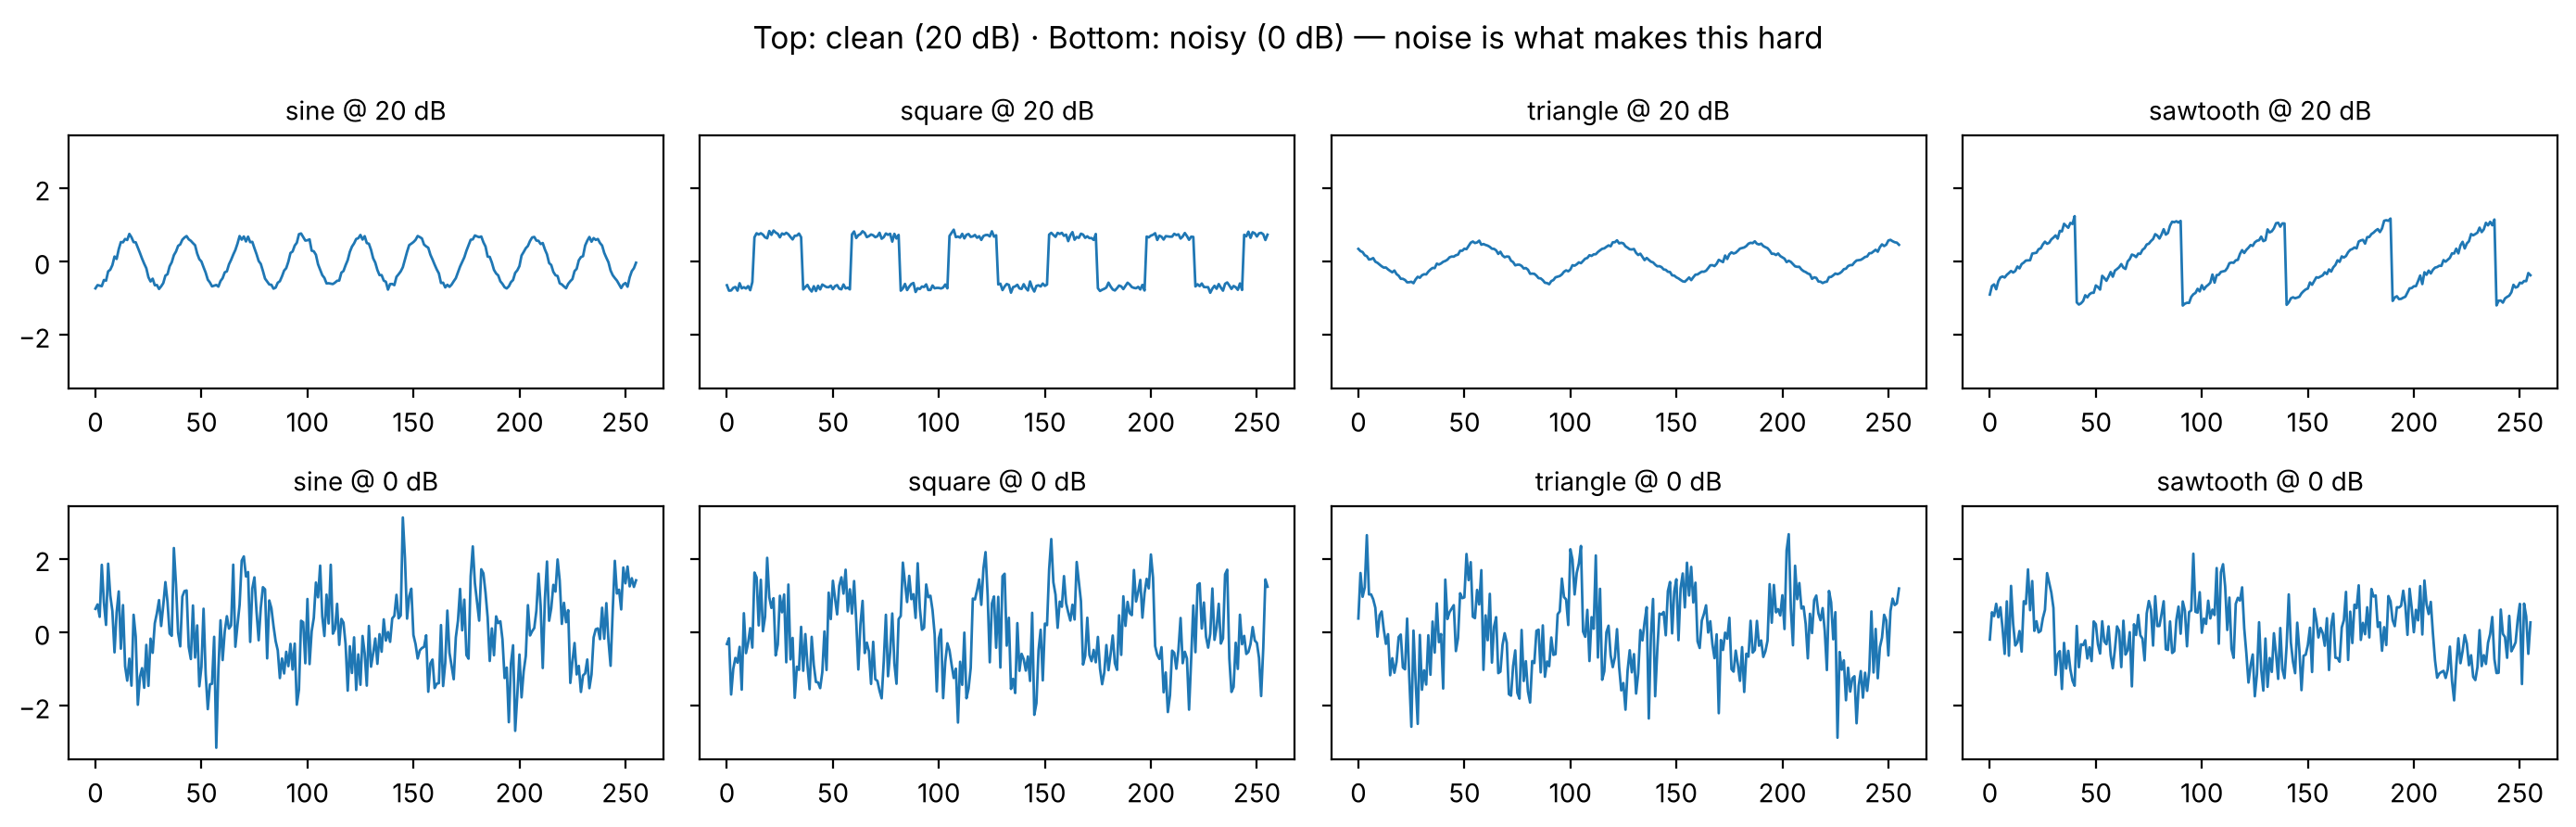

In [3]:
print("Samples per class:", dict(zip(CLASSES, np.bincount(y))))
fig, ax = plt.subplots(2, 4, figsize=(14, 4.5), sharey=True)
for ci, c in enumerate(CLASSES):
    for r, s in enumerate([20, 0]):
        i = np.where((y == ci) & (snr == s))[0][0]
        ax[r, ci].plot(X[i], lw=1); ax[r, ci].set_title(f"{c} @ {s} dB", fontsize=10)
plt.suptitle("Top: clean (20 dB) · Bottom: noisy (0 dB) — noise is what makes this hard"); plt.tight_layout(); plt.show()

## Step 4 — Preprocess
Two Unit 5 ideas:

* **Normalization** — make each input have mean 0 and standard deviation 1, so neurons don't saturate and amplitude differences don't confuse the network: pⁿ = (p − mean) / std.
* **Coding targets** — one-of-N: class 2 → [0, 0, 1, 0]. Keras does this for us when we use `sparse_categorical_crossentropy`, so we keep integer labels.

🔁 **CHANGE FOR YOUR THEME** — images: divide by 255 (or use the pretrained model's preprocess). Tabular: standardize each column using **training-set** statistics only.

In [4]:
def normalize_per_sample(A):
    return (A - A.mean(axis=1, keepdims=True)) / (A.std(axis=1, keepdims=True) + 1e-8)

Xn = normalize_per_sample(X)[..., None]      # shape (N, 256, 1) for a 1-D CNN
print("after normalization: mean %.3f, std %.3f" % (Xn.mean(), Xn.std()), "| shape", Xn.shape)

after normalization: mean -0.000, std 1.000 | shape (12800, 256, 1)


## Step 5 — Split into training / validation / test (70 / 15 / 15)
* **Training** — changes the weights. **Validation** — decides when to stop. **Test** — the final, honest exam; touched **once**.
* `stratify` keeps the same class (and SNR) mix in every set.
* 🔁 For patient / speaker / machine data, split **by person or machine**, not by sample, or you will leak information (that is exactly the Hard path in Themes 1 and 3).

In [5]:
strat = y * 100 + (snr + 10)                 # stratify on class AND SNR
idx = np.arange(len(y))
i_tr, i_tmp = train_test_split(idx, test_size=0.30, random_state=SEED, stratify=strat)
i_va, i_te  = train_test_split(i_tmp, test_size=0.50, random_state=SEED, stratify=strat[i_tmp])
Xtr, ytr, Xva, yva, Xte, yte = Xn[i_tr], y[i_tr], Xn[i_va], y[i_va], Xn[i_te], y[i_te]
print(f"train {len(i_tr)} | val {len(i_va)} | test {len(i_te)}")
assert not (set(i_tr) & set(i_te)), "LEAK: a sample is in both train and test!"

train 8960 | val 1920 | test 1920


## Step 6 — Baseline first
A simple model gives a number to beat. If your neural network can't beat it, something is wrong.

Sample baseline: **logistic regression on the FFT magnitude** (a classic signal-processing feature).

In [6]:
def fft_feats(A): return np.abs(np.fft.rfft(A[..., 0], axis=1))
base = LogisticRegression(max_iter=2000).fit(fft_feats(Xtr), ytr)
base_acc = accuracy_score(yte, base.predict(fft_feats(Xte)))
print(f"Baseline test accuracy (all SNRs): {base_acc:.3f}")

Baseline test accuracy (all SNRs): 0.601


## Step 7 — Build the network
🔁 **CHANGE FOR YOUR THEME** — choose by input type:

| Input | Good first network |
|---|---|
| 1-D signal (ECG, I/Q, vibration, audio) | 1-D CNN (this sample) |
| Image (leaves, roads) | Pretrained CNN (MobileNetV2) + new softmax head |
| Table of numbers (sensors, AQI) | MLP: Dense(64, relu) → Dense(32, relu) → output |
| Time series to forecast | MLP on a window of past values, or LSTM |

Design notes: **ReLU** hidden layers train faster than sigmoid; **softmax** output for classes; **Dropout** fights overfitting. Keras starts weights with **Glorot uniform** — small random values, not zero (Unit 5, weight initialization).

In [7]:
def build_cnn(n_classes=len(CLASSES), input_len=N_SAMPLES):
    return keras.Sequential([
        layers.Input((input_len, 1)),
        layers.Conv1D(16, 7, activation="relu", padding="same"), layers.MaxPooling1D(2),
        layers.Conv1D(32, 5, activation="relu", padding="same"), layers.MaxPooling1D(2),
        layers.Conv1D(32, 3, activation="relu", padding="same"),
        layers.GlobalAveragePooling1D(),
        layers.Dropout(0.3),
        layers.Dense(n_classes, activation="softmax"),
    ])

model = build_cnn()
model.compile(optimizer=keras.optimizers.Adam(CONFIG["learning_rate"]),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()
print("Parameters:", model.count_params())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 256, 16)        │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 128, 16)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 128, 32)        │         2,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 64, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 64, 32)         │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,956 (23.27 KB)

 Trainable params: 5,956 (23.27 KB)

 Non-trainable params: 0 (0.00 B)

Parameters: 5956


## Step 8 — Train with early stopping
Backpropagation + Adam. **Early stopping** watches the validation loss and keeps the weights from the best epoch (Unit 5, stopping criteria).

trained 40 epochs in 30s


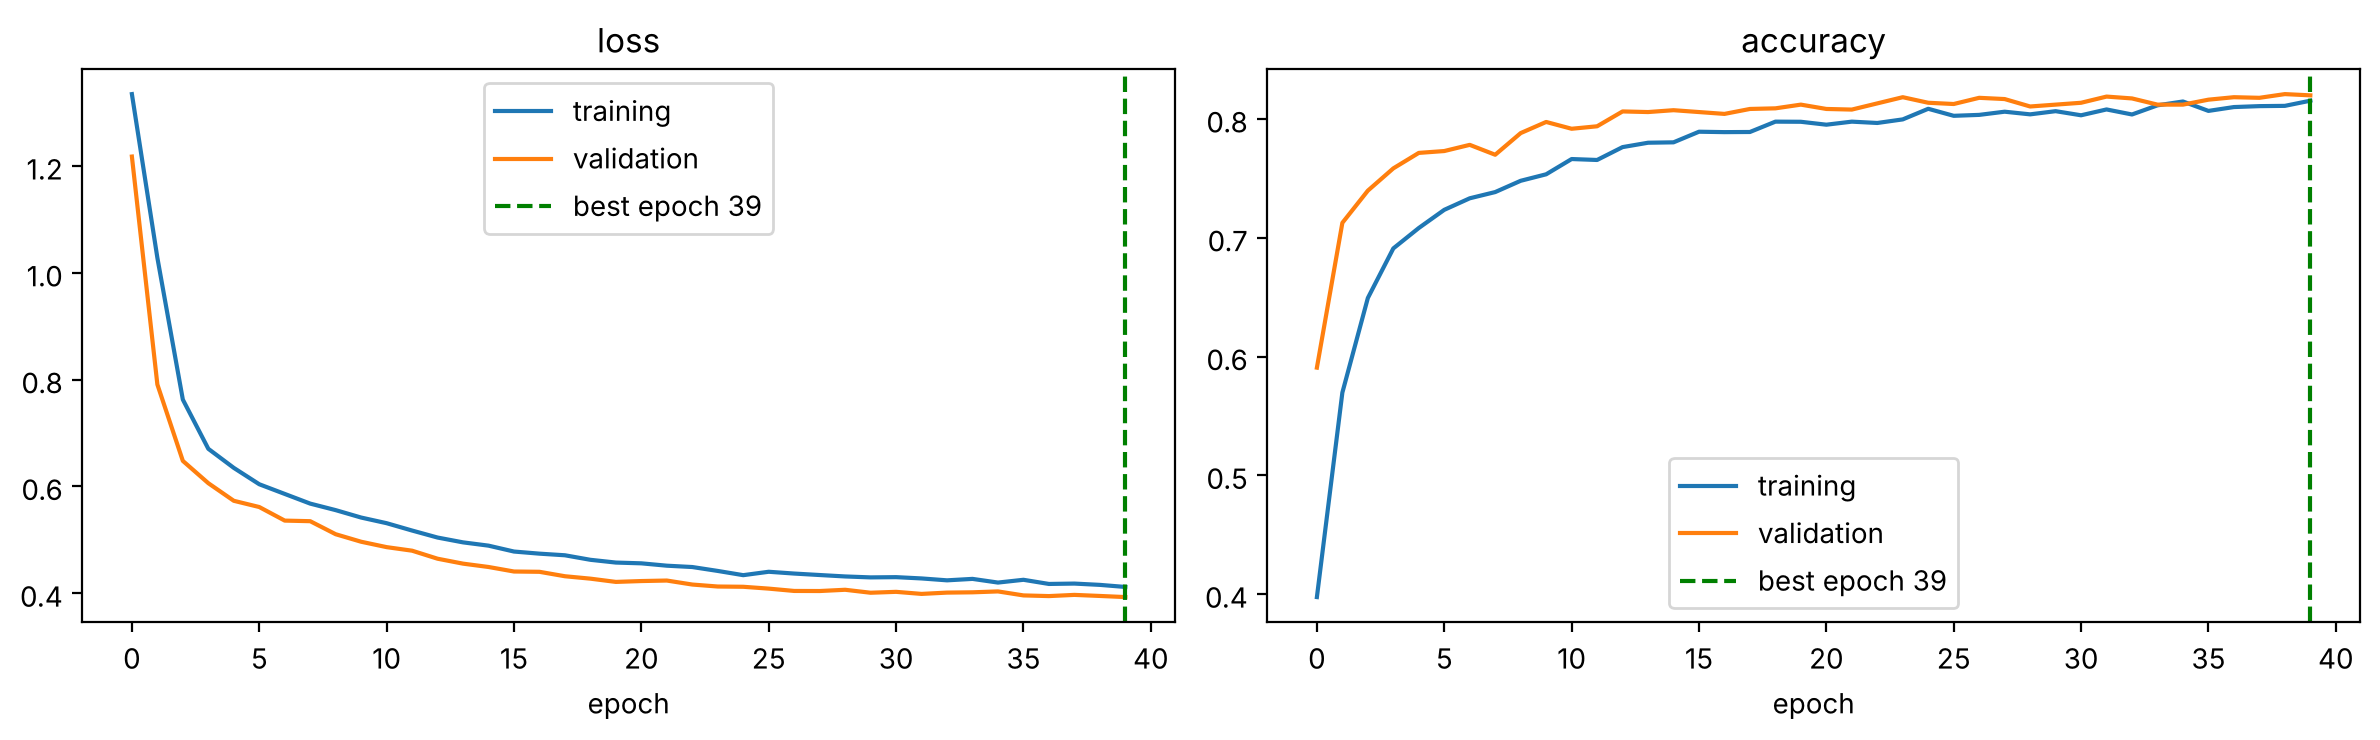

If validation loss rises while training loss keeps falling → overfitting.


In [8]:
def train(m, Xa, ya, Xv, yv, verbose=0):
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=CONFIG["patience"], restore_best_weights=True)
    t0 = time.time()
    h = m.fit(Xa, ya, validation_data=(Xv, yv), epochs=CONFIG["epochs"],
              batch_size=CONFIG["batch_size"], callbacks=[es], verbose=verbose)
    print(f"trained {len(h.history['loss'])} epochs in {time.time()-t0:.0f}s")
    return h

hist = train(model, Xtr, ytr, Xva, yva)
best = int(np.argmin(hist.history["val_loss"]))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for k, a in zip(["loss", "accuracy"], ax):
    a.plot(hist.history[k], label="training"); a.plot(hist.history["val_" + k], label="validation")
    a.axvline(best, ls="--", c="g", label=f"best epoch {best}"); a.set_title(k); a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.show()
print("If validation loss rises while training loss keeps falling → overfitting.")

## Step 9 — Evaluate on the test set (once!)
Unit 5 post-training analysis for **pattern recognition**: accuracy, per-class precision/recall, **confusion matrix**, **ROC / AUC**.

🔁 Fitting problems instead: RMSE/MAE, regression of output vs target (slope m, offset c, R). Segmentation: IoU per class.

Test accuracy, all SNRs : 0.833   (baseline 0.601)
Test accuracy, SNR>=10dB: 0.997   (Foundation target 0.95)
Macro one-vs-rest AUC   : 0.973

              precision    recall  f1-score   support

        sine      0.803     0.704     0.750       480
      square      0.846     0.902     0.873       480
    triangle      0.779     0.777     0.778       480
    sawtooth      0.898     0.950     0.923       480

    accuracy                          0.833      1920
   macro avg      0.831     0.833     0.831      1920
weighted avg      0.831     0.833     0.831      1920



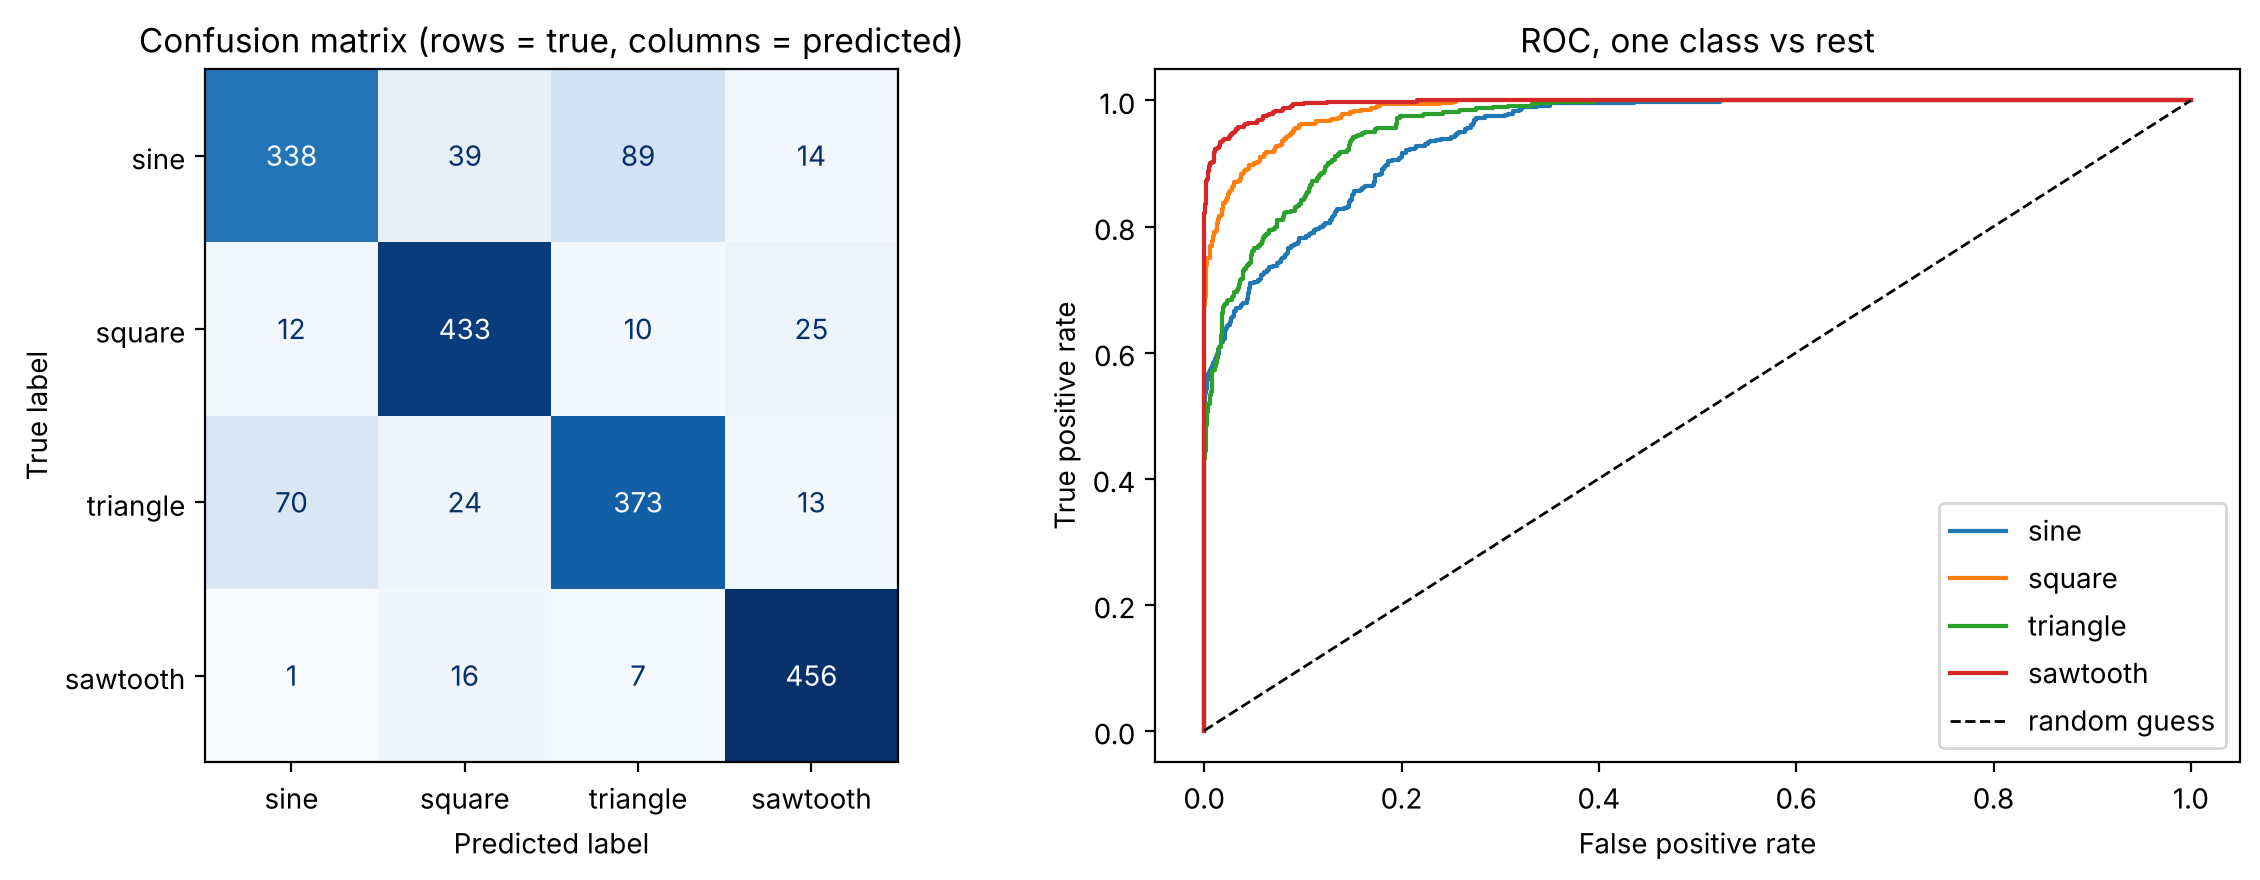

In [9]:
p_te = model.predict(Xte, verbose=0); yhat = p_te.argmax(1)
test_acc = accuracy_score(yte, yhat)
hi = snr[i_te] >= 10
acc_hi = accuracy_score(yte[hi], yhat[hi])
auc = roc_auc_score(yte, p_te, multi_class="ovr")
print(f"Test accuracy, all SNRs : {test_acc:.3f}   (baseline {base_acc:.3f})")
print(f"Test accuracy, SNR>=10dB: {acc_hi:.3f}   (Foundation target {CONFIG['target_value']})")
print(f"Macro one-vs-rest AUC   : {auc:.3f}\n")
print(classification_report(yte, yhat, target_names=CLASSES, digits=3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(confusion_matrix(yte, yhat), display_labels=CLASSES).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Confusion matrix (rows = true, columns = predicted)")
for ci, c in enumerate(CLASSES):
    fpr, tpr, _ = roc_curve(yte == ci, p_te[:, ci]); ax[1].plot(fpr, tpr, label=c)
ax[1].plot([0, 1], [0, 1], "k--", lw=1, label="random guess"); ax[1].set_xlabel("False positive rate")
ax[1].set_ylabel("True positive rate"); ax[1].set_title("ROC, one class vs rest"); ax[1].legend()
plt.tight_layout(); plt.show()

## Step 10 — Error analysis: *where* and *why* does it fail?
Judges give 20 marks for insight. Plot performance against the operating condition (here SNR) and look at real mistakes.

🔁 Your condition might be: patient, motor load, city, speaker, light level, image class.

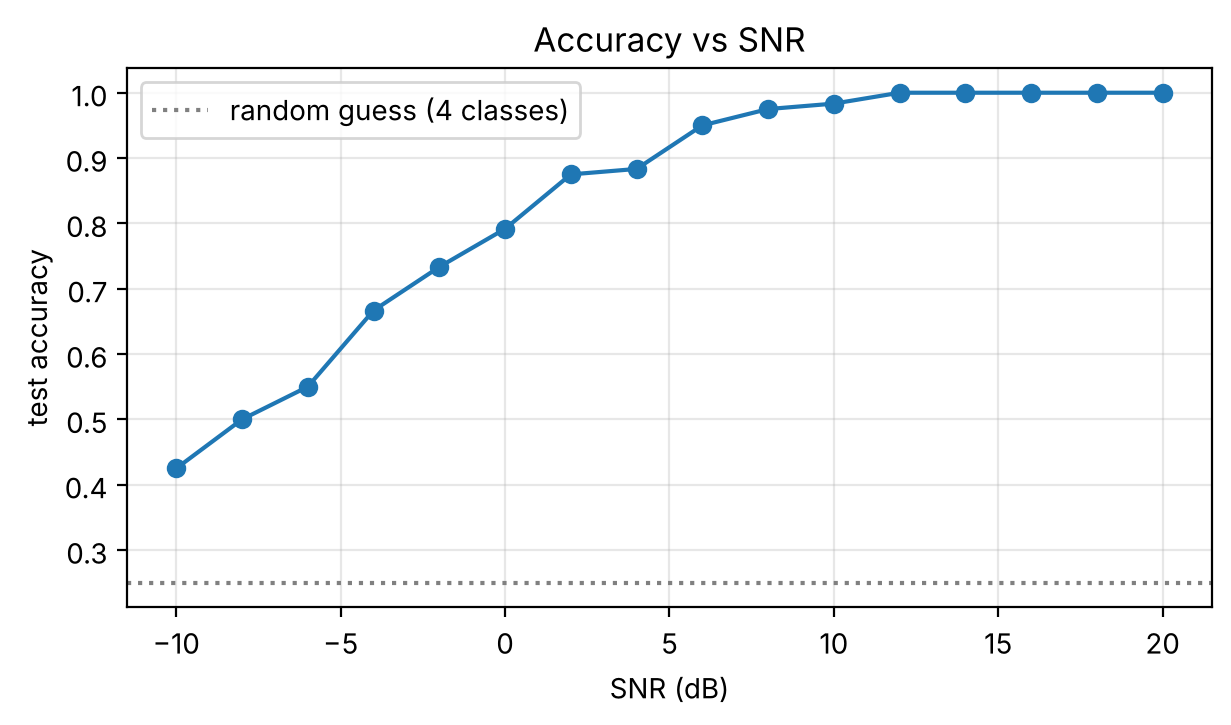

320 mistakes out of 1920. Three examples:


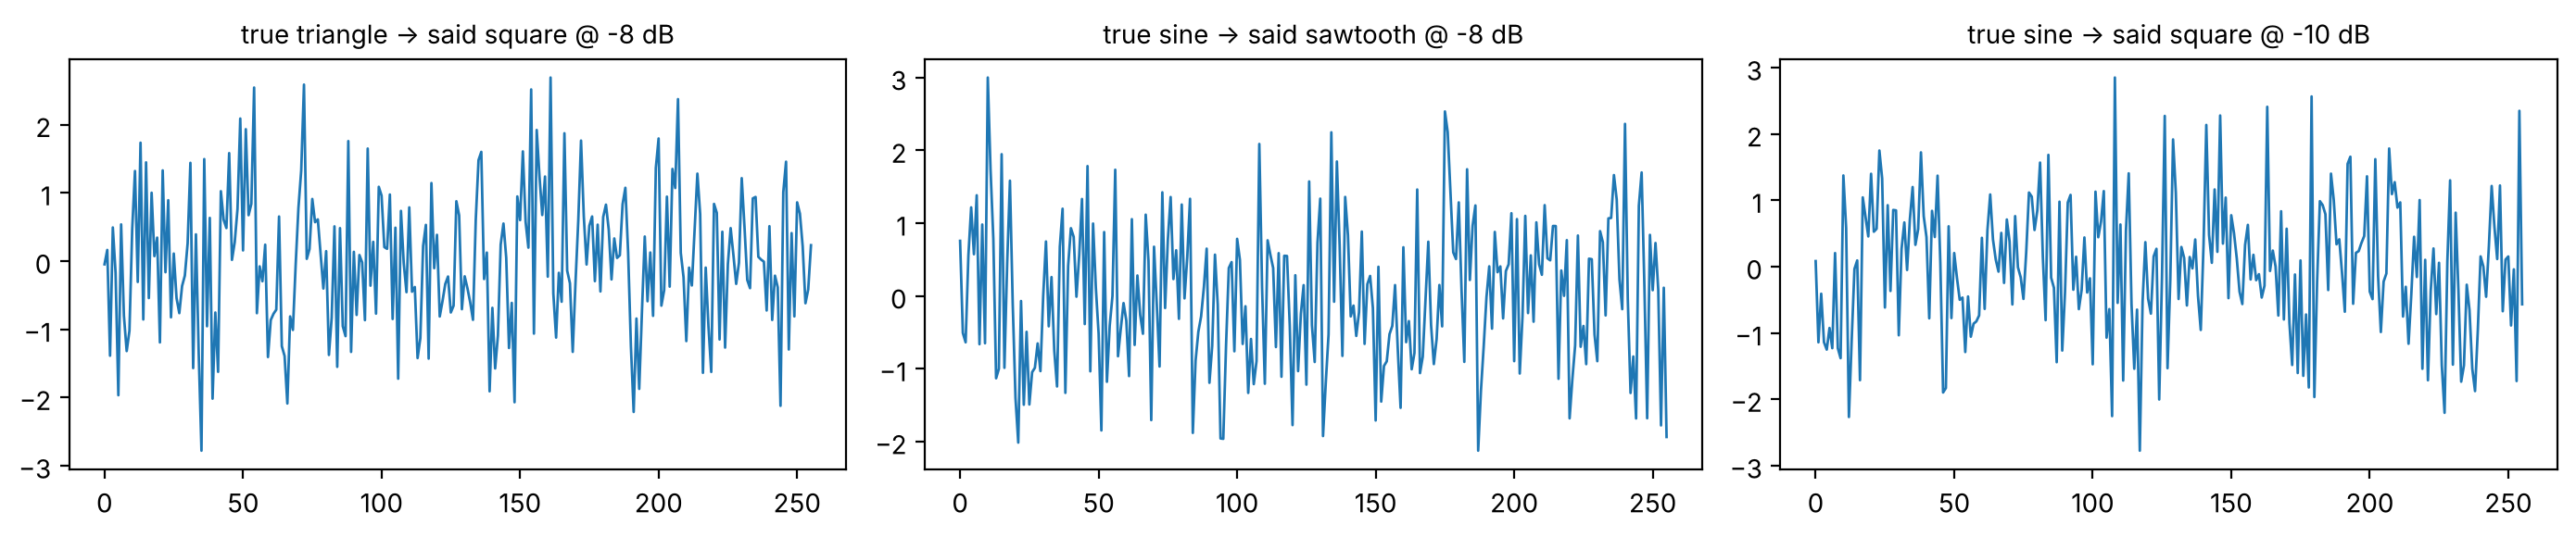

In [10]:
snr_te = snr[i_te]
acc_by_snr = [accuracy_score(yte[snr_te == s], yhat[snr_te == s]) for s in SNRS]
plt.figure(figsize=(7, 3.5)); plt.plot(SNRS, acc_by_snr, "o-")
plt.axhline(0.25, ls=":", c="gray", label="random guess (4 classes)")
plt.xlabel("SNR (dB)"); plt.ylabel("test accuracy"); plt.title("Accuracy vs SNR"); plt.grid(alpha=.3); plt.legend(); plt.show()

wrong = np.where(yhat != yte)[0]
print(f"{len(wrong)} mistakes out of {len(yte)}. Three examples:")
fig, ax = plt.subplots(1, 3, figsize=(14, 3))
for a, k in zip(ax, wrong[:3]):
    a.plot(Xte[k, :, 0], lw=1)
    a.set_title(f"true {CLASSES[yte[k]]} → said {CLASSES[yhat[k]]} @ {snr_te[k]} dB", fontsize=10)
plt.tight_layout(); plt.show()

## Step 11 — Hard path: generalise to conditions you never trained on
**The trap (Unit 5 — extrapolation):** train only on clean signals (SNR ≥ 10 dB), then test on noisy ones (SNR ≤ 0 dB). Training and validation look great; the test collapses.

**The fix:** *data augmentation* — while training, add random noise to the clean signals so the network has seen "noisy-looking" inputs, without using any real low-SNR data.

In [11]:
clean_tr = snr[i_tr] >= 10; clean_va = snr[i_va] >= 10; noisy_te = snr[i_te] <= 0
Xc_tr, yc_tr = Xtr[clean_tr], ytr[clean_tr]; Xc_va, yc_va = Xva[clean_va], yva[clean_va]

# (a) the trap: clean-only training
m_clean = build_cnn(); m_clean.compile(optimizer=keras.optimizers.Adam(CONFIG["learning_rate"]), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
train(m_clean, Xc_tr, yc_tr, Xc_va, yc_va)
acc_trap = accuracy_score(yte[noisy_te], m_clean.predict(Xte[noisy_te], verbose=0).argmax(1))

# (b) the fix: augment the same clean signals with random noise (-10..+10 dB)
def augment(A, rng=np.random.RandomState(1)):
    out = []
    for a in A[..., 0]:
        out.append(add_noise(a, rng.uniform(-10, 10), rng=rng))
    return normalize_per_sample(np.array(out, dtype="float32"))[..., None]
Xaug = np.concatenate([Xc_tr, augment(Xc_tr)]); yaug = np.concatenate([yc_tr, yc_tr])
m_aug = build_cnn(); m_aug.compile(optimizer=keras.optimizers.Adam(CONFIG["learning_rate"]), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
train(m_aug, Xaug, yaug, Xc_va, yc_va)
acc_fix = accuracy_score(yte[noisy_te], m_aug.predict(Xte[noisy_te], verbose=0).argmax(1))

print(f"\nTest accuracy on NOISY signals (SNR <= 0 dB), never seen in training:")
print(f"  clean-only training : {acc_trap:.3f}")
print(f"  + noise augmentation: {acc_fix:.3f}")
print(f"Model size: {m_aug.count_params()} parameters (hard-path limit 20,000)")

trained 40 epochs in 16s


trained 40 epochs in 24s



Test accuracy on NOISY signals (SNR <= 0 dB), never seen in training:
  clean-only training : 0.360
  + noise augmentation: 0.588
Model size: 5956 parameters (hard-path limit 20,000)


## Step 12 — Sensitivity / saliency, then the slide summary
**Sensitivity analysis (Unit 5):** the derivative of the output with respect to each input sample, ∂a/∂p, tells which parts of the input the network relied on. For a square wave it should light up the sharp edges.

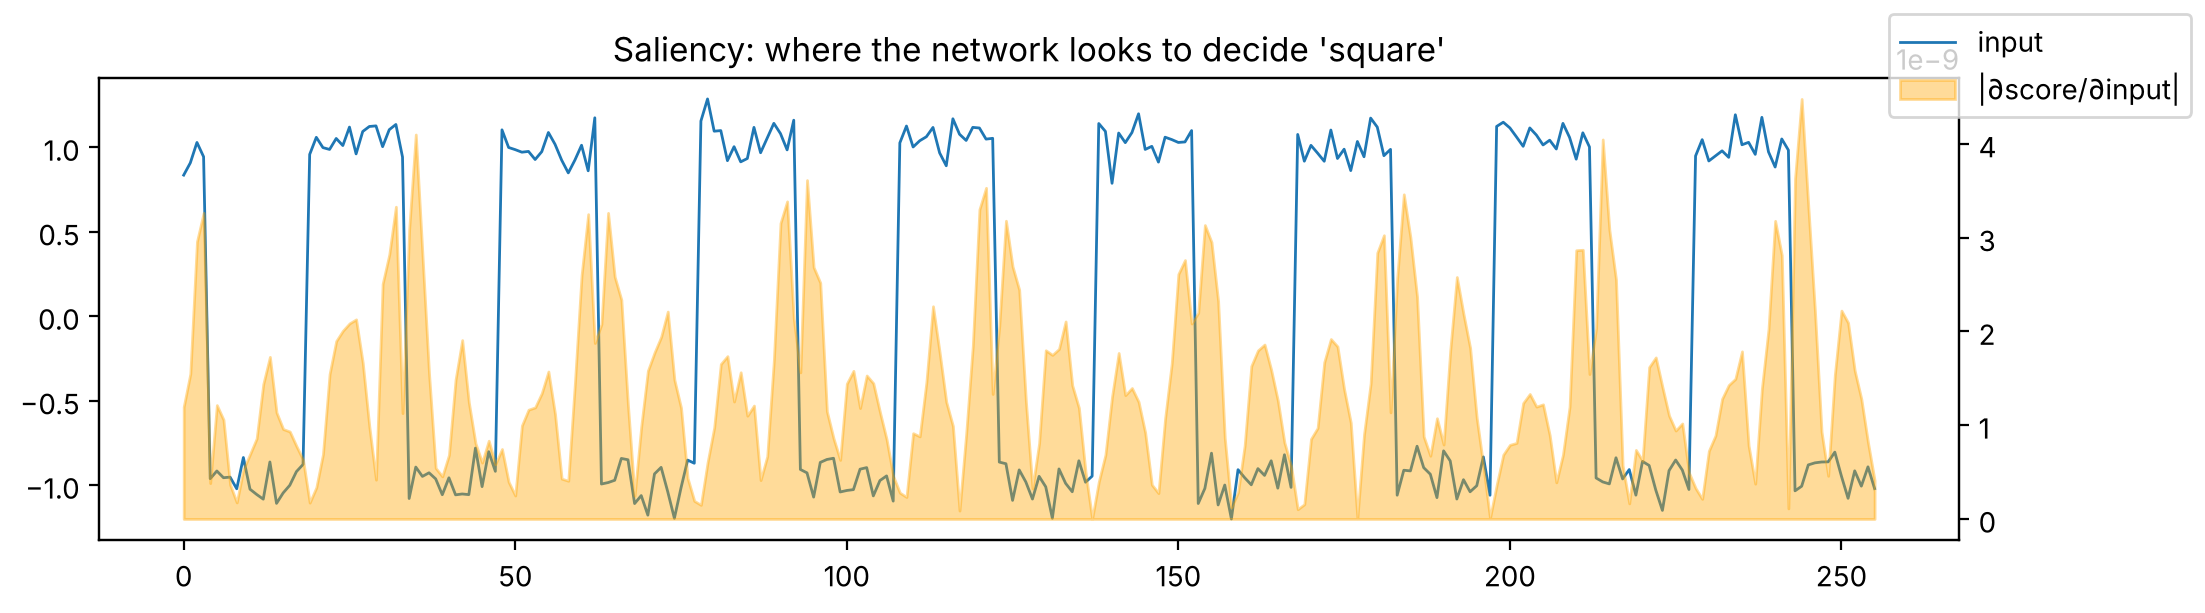


========== RESULTS FOR SLIDE 3 ==========
Theme / tier                             Theme 0 - Signal Type Recognition (sample) / Hard path
Baseline (FFT + logistic), all SNRs      0.601
1-D CNN, all SNRs                        0.833
1-D CNN, SNR >= 10 dB (target 0.95)      0.997  PASS
Macro AUC                                0.973
Hard path: clean-only -> noisy test      0.360
Hard path: + noise augmentation          0.588
Parameters / size (float32)              5956 / 23 KB
Latency per sample (CPU)                 0.31 ms


In [12]:
k = np.where((yte == 1) & (snr_te == 20))[0][0]           # a clean square wave
x = tf.convert_to_tensor(Xte[k:k+1])
with tf.GradientTape() as tape:
    tape.watch(x); score = model(x)[0, yte[k]]
sal = np.abs(tape.gradient(score, x).numpy()[0, :, 0])
fig, ax = plt.subplots(figsize=(12, 3)); ax.plot(Xte[k, :, 0], lw=1, label="input")
ax2 = ax.twinx(); ax2.fill_between(range(N_SAMPLES), sal, color="orange", alpha=.4, label="|∂score/∂input|")
ax.set_title("Saliency: where the network looks to decide 'square'"); fig.legend(loc="upper right"); plt.show()

# latency per sample
t0 = time.time(); model.predict(Xte[:500], verbose=0); ms = (time.time() - t0) / 500 * 1000

print("\n========== RESULTS FOR SLIDE 3 ==========")
rows = [("Theme / tier", f"{CONFIG['theme']} / {CONFIG['tier']}"),
        ("Baseline (FFT + logistic), all SNRs", f"{base_acc:.3f}"),
        ("1-D CNN, all SNRs", f"{test_acc:.3f}"),
        ("1-D CNN, SNR >= 10 dB (target 0.95)", f"{acc_hi:.3f}  {'PASS' if acc_hi >= CONFIG['target_value'] else 'BELOW TARGET'}"),
        ("Macro AUC", f"{auc:.3f}"),
        ("Hard path: clean-only -> noisy test", f"{acc_trap:.3f}"),
        ("Hard path: + noise augmentation", f"{acc_fix:.3f}"),
        ("Parameters / size (float32)", f"{model.count_params()} / {model.count_params()*4/1024:.0f} KB"),
        ("Latency per sample (CPU)", f"{ms:.2f} ms")]
for a, b in rows: print(f"{a:<40} {b}")

## Presentation checklist (3 minutes)
1. **Problem & tier (30 s)** — Step 1 table, target number.
2. **Approach (60 s)** — network diagram from Step 7; what you changed from the baseline and *why*.
3. **Result (60 s)** — the slide-3 table above + one plot (confusion matrix, accuracy vs SNR) + **one failure case** with your explanation (Step 10).
4. **Live proof (30 s)** — run one prediction live.

### Before you submit
- [ ] Runtime → *Restart and run all* finishes without errors in < 10 minutes
- [ ] Test set used **once**, only in Step 9 onwards
- [ ] Every pretrained model / library you used is named on slide 2